<a href="https://colab.research.google.com/github/incrisvel/adaptaste/blob/main/parsing_ner_er.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip -q install spacy networkx matplotlib
!python -m spacy download pt_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 34.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
import spacy
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from spacy import displacy

nlp = spacy.load("pt_core_news_sm")

print(nlp.pipe_names)
print("spaCy:", spacy.__version__, "| Modelo:", nlp.meta["version"])

['tok2vec', 'morphologizer', 'parser', 'lemmatizer', 'attribute_ruler', 'ner']
spaCy: 3.8.16 | Modelo: 3.8.0


## Dependências sintáticas e árvores

In [ ]:
def analyze_dependency(text):
    doc = nlp(text)

    dependency_df = [
        {
            "token": token.text,
            "lemma": token.lemma_,
            "grammar_class": token.pos_,
            "dependency": token.dep_,
            "governance_token": token.head.text
        }
        for token in doc
    ]
    return doc, pd.DataFrame(dependency_df)

example_text = (
    "A comida estava deliciosa, "
    "mas o atendimento foi demorado."
)

doc, dependency_df = analyze_dependency(example_text)

display(dependency_df)

,token,lemma,grammar_class,dependency,governance_token
0,A,o,DET,det,comida
1,comida,comida,NOUN,nsubj,deliciosa
2,estava,estar,AUX,cop,deliciosa
3,deliciosa,delicioso,ADJ,ROOT,deliciosa
4,",",",",PUNCT,punct,demorado
5,mas,mas,CCONJ,cc,demorado
6,o,o,DET,det,atendimento
7,atendimento,atendimento,NOUN,nsubj:pass,demorado
8,foi,ser,AUX,aux:pass,demorado
9,demorado,demorar,VERB,conj,deliciosa


In [ ]:
displacy.render(
    doc,
    style="dep",
    jupyter=True,
    options={"compact": True}
)

## Reconhecimento de entidades nomeadas (NER)

In [4]:
import pandas as pd
import json

# Abre arquivo de reviews
with open('reviews_preprocessed.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

preprocessed_reviews_df = pd.DataFrame(
    review
    for review in data
)

# Guarda: o restante do notebook assume o export com nota. Um arquivo antigo
# (sem rating) passaria em silêncio e geraria resultados errados.
required_fields = {"rating", "review_text"}
missing_fields = required_fields - set(preprocessed_reviews_df.columns)

if missing_fields:
    raise ValueError(
        f"Arquivo sem os campos obrigatórios {sorted(missing_fields)}: "
        "confira se é o reviews_preprocessed.json com rating."
    )

print(f"Reviews carregadas: {len(preprocessed_reviews_df)}")
print(f"Colunas: {list(preprocessed_reviews_df.columns)}")

preprocessed_reviews_df.head()


Reviews carregadas: 2262
Colunas: ['review_id', 'review_date', 'place_id', 'review_text', 'rating', 'description_clean', 'description_tokenized', 'description_normalized', 'description_no_stopwords', 'description_stemmed', 'description_lemmatized', 'description_bigrams']


,review_id,review_date,place_id,review_text,rating,description_clean,description_tokenized,description_normalized,description_no_stopwords,description_stemmed,description_lemmatized,description_bigrams
0,Ci9DQUlRQUNvZENodHljRjlvT2xaVlRqSXpPRTFSYURKdl...,2026-07-30T17:09:02+00:00,0x6b0a883715bb4c6b:0,Excelente restaurante! A comida é muito saboro...,5.0,Excelente restaurante! A comida é muito saboro...,"[Excelente, restaurante, !, A, comida, é, muit...","[excelente, restaurante, a, comida, é, muito, ...","[excelente, restaurante, comida, muito, saboro...","[excel, restaurant, com, muit, sabor, bem, ser...","[excelente, restaurante, comer, muito, saboros...","[[excelente, restaurante], [restaurante, comer..."
1,Ci9DQUlRQUNvZENodHljRjlvT20xVFVVaHpaRVV4VVZWSl...,2026-05-31T17:09:02+00:00,0x6b0a883715bb4c6b:0,Fui pela primeira vez e gostei bastante! A com...,5.0,Fui pela primeira vez e gostei bastante! A com...,"[Fui, pela, primeira, vez, e, gostei, bastante...","[fui, pela, primeira, vez, e, gostei, bastante...","[primeira, vez, gostei, bastante, comida, muit...","[prim, vez, gost, bast, com, muit, sabor, peg,...","[primeiro, vez, gostar, bastante, comer, muito...","[[primeiro, vez], [vez, gostar], [gostar, bast..."
2,Ci9DQUlRQUNvZENodHljRjlvT2psSmFEVkVNak5NTnpONV...,2026-05-31T17:09:02+00:00,0x6b0a883715bb4c6b:0,Ambiente simples e gostoso familiar comida óti...,5.0,Ambiente simples e gostoso familiar comida óti...,"[Ambiente, simples, e, gostoso, familiar, comi...","[ambiente, simples, e, gostoso, familiar, comi...","[ambiente, simples, gostoso, familiar, comida,...","[ambi, simpl, gost, famili, com, ótim, gost, m...","[ambiente, simples, gostoso, familiar, comer, ...","[[ambiente, simples], [simples, gostoso], [gos..."
3,ChZDSUhNMG9nS0VJQ0FnSUNHMWZEb1NBEAE,2022-08-30T17:10:53+00:00,0x6b0a883715bb4c6b:0,"Se é qualidade que procura, não tem outra igua...",5.0,"Se é qualidade que procura, não tem outra igua...","[Se, é, qualidade, que, procura, ,, não, tem, ...","[se, é, qualidade, que, procura, não, tem, out...","[qualidade, procura, não, outra, igual, agilid...","[qual, proc, não, outr, igual, agil, entreg, t...","[qualidade, procurar, não, outro, igual, agili...","[[qualidade, procurar], [procurar, não], [não,..."
4,ChdDSUhNMG9nS0VJQ0FnSUNHc2NtMjRBRRAB,2022-08-30T17:10:52+00:00,0x6b0a883715bb4c6b:0,"Comida maravilhosa. Super caseira, bem tempera...",5.0,"Comida maravilhosa. Super caseira, bem tempera...","[Comida, maravilhosa, ., Super, caseira, ,, be...","[comida, maravilhosa, super, caseira, bem, tem...","[comida, maravilhosa, super, caseira, bem, tem...","[com, maravilh, sup, cas, bem, temper, tend, s...","[comida, maravilhoso, super, caseira, bem, tem...","[[comida, maravilhoso], [maravilhoso, super], ..."


In [5]:
def extract_entities(texto):
    return pd.DataFrame([
        {
            "entity": ent.text,
            "category": ent.label_,
            "start": ent.start_char,
            "end": ent.end_char
        }
        for ent in nlp(texto).ents
    ], columns=["entity", "category", "start", "end"])


In [6]:
# Extrai todos os textos
texts = preprocessed_reviews_df["review_text"].fillna("").astype(str).tolist()

docs = list(
    nlp.pipe(
        texts,
        batch_size=32
    )
)

entity_records = []

for row_index, doc in enumerate(docs):
    for ent in doc.ents:
        entity_records.append({
            "review_index": row_index,
            "review_text": preprocessed_reviews_df.iloc[row_index]["review_text"],
            "entity": ent.text,
            "entity_category": ent.label_,
            "start": ent.start_char,
            "end": ent.end_char,
            "place_id": (
                preprocessed_reviews_df.iloc[row_index]["place_id"]
                if "place_id" in preprocessed_reviews_df.columns
                else None
            ),
            "review_id": (
                preprocessed_reviews_df.iloc[row_index]["review_id"]
            ),
        })

entities_df = pd.DataFrame(entity_records)

# Estiliza a exibição limitando o tamanho da coluna review_id
styled_df = entities_df.head(20).style.set_properties(
    **{
        'max-width': '100px',
        'overflow': 'hidden',
        'text-overflow': 'ellipsis',
        'white-space': 'nowrap'
    },
    subset=['review_id', 'place_id']
)

display(styled_df)

,review_index,review_text,entity,entity_category,start,end,place_id,review_id
0,1,"Fui pela primeira vez e gostei bastante! A comida é muito saborosa. Pegamos as opções sem pimenta/menos picantes por sugestão de amigos e valeu super a pena - mesmo ficando com curiosidade de experimentar os pratos apimentados. Os atendentes são uns queridos e o ambiente, apesar de simples, é aconchegante - com músicas coreanas tocando em volume agradável e decorações. Além disso eles tem estacionamento próprio.",Fui,PER,0,3,0x6b0a883715bb4c6b:0,Ci9DQUlRQUNvZENodHljRjlvT20xVFVVaHpaRVV4VVZWSllWZFpPVEZEUzNWdFdtYxAB
1,2,Ambiente simples e gostoso familiar comida ótima gostamos muito moramos em Barra Velha e fomos comemorar dia das mães com nossa filha gostamos bastante,Barra Velha,LOC,75,86,0x6b0a883715bb4c6b:0,Ci9DQUlRQUNvZENodHljRjlvT2psSmFEVkVNak5NTnpONVRWRTNUMmxwVTBOaVltYxAB
2,3,"Se é qualidade que procura, não tem outra igual. Agilidade na entrega e tudo muito gostoso, opções de sabores, gosto muito da refeição dessa equipe. Parabéns!",Parabéns,MISC,149,157,0x6b0a883715bb4c6b:0,ChZDSUhNMG9nS0VJQ0FnSUNHMWZEb1NBEAE
3,4,"Comida maravilhosa. Super caseira, bem temperada mesmo tendo sido congelada, depois de aquecer tem gostinho de comida feita na hora. Super recomendo para as pessoas de Blumenau",Super,MISC,20,25,0x6b0a883715bb4c6b:0,ChdDSUhNMG9nS0VJQ0FnSUNHc2NtMjRBRRAB
4,4,"Comida maravilhosa. Super caseira, bem temperada mesmo tendo sido congelada, depois de aquecer tem gostinho de comida feita na hora. Super recomendo para as pessoas de Blumenau",Super,MISC,133,138,0x6b0a883715bb4c6b:0,ChdDSUhNMG9nS0VJQ0FnSUNHc2NtMjRBRRAB
5,4,"Comida maravilhosa. Super caseira, bem temperada mesmo tendo sido congelada, depois de aquecer tem gostinho de comida feita na hora. Super recomendo para as pessoas de Blumenau",Blumenau,LOC,168,176,0x6b0a883715bb4c6b:0,ChdDSUhNMG9nS0VJQ0FnSUNHc2NtMjRBRRAB
6,5,"As palavras para descrever a comida é simplesmente SENSACIONAL. Muito sabor, tudo muito fresco, além de ser muito gostoso o que eles fazem. RECOMENDADÍSSIMO. Podiam trazer uma franquia dessa para São Paulo. A próxima vez que estivermos passeando em Blumenau com certeza traremos mais. Uma pena não ter pego mais.",SENSACIONAL,ORG,51,62,0x6b0a883715bb4c6b:0,ChZDSUhNMG9nS0VJQ0FnSUNHc1pPSlNREAE
7,5,"As palavras para descrever a comida é simplesmente SENSACIONAL. Muito sabor, tudo muito fresco, além de ser muito gostoso o que eles fazem. RECOMENDADÍSSIMO. Podiam trazer uma franquia dessa para São Paulo. A próxima vez que estivermos passeando em Blumenau com certeza traremos mais. Uma pena não ter pego mais.",RECOMENDADÍSSIMO,MISC,140,156,0x6b0a883715bb4c6b:0,ChZDSUhNMG9nS0VJQ0FnSUNHc1pPSlNREAE
8,5,"As palavras para descrever a comida é simplesmente SENSACIONAL. Muito sabor, tudo muito fresco, além de ser muito gostoso o que eles fazem. RECOMENDADÍSSIMO. Podiam trazer uma franquia dessa para São Paulo. A próxima vez que estivermos passeando em Blumenau com certeza traremos mais. Uma pena não ter pego mais.",São Paulo,LOC,196,205,0x6b0a883715bb4c6b:0,ChZDSUhNMG9nS0VJQ0FnSUNHc1pPSlNREAE
9,5,"As palavras para descrever a comida é simplesmente SENSACIONAL. Muito sabor, tudo muito fresco, além de ser muito gostoso o que eles fazem. RECOMENDADÍSSIMO. Podiam trazer uma franquia dessa para São Paulo. A próxima vez que estivermos passeando em Blumenau com certeza traremos mais. Uma pena não ter pego mais.",Blumenau,LOC,249,257,0x6b0a883715bb4c6b:0,ChZDSUhNMG9nS0VJQ0FnSUNHc1pPSlNREAE


In [ ]:
displacy.render(nlp(texts[5]), style="ent", jupyter=True)

## NER no corpus

A extração roda no corpus inteiro, e não em uma frase de exemplo. O que interessa verificar é
quantas reviews têm entidade e o que o modelo é capaz de reconhecer: o `pt_core_news_sm` tem
taxonomia fechada, e prato de restaurante não faz parte dela. É essa taxonomia que limita a
utilidade de NER nestes dados.


In [ ]:
# Taxonomia do modelo
print("Categorias reconhecidas:", nlp.get_pipe("ner").labels)

total_reviews = len(preprocessed_reviews_df)
reviews_with_entity = entities_df["review_index"].nunique()

print(f"\nReviews no corpus: {total_reviews}")
print(
    "Reviews com pelo menos uma entidade: "
    f"{reviews_with_entity} ({reviews_with_entity / total_reviews:.1%})"
)
print(f"Entidades extraídas: {len(entities_df)}")
print(f"Entidades por review (média): {len(entities_df) / total_reviews:.2f}")

display(
    entities_df["entity_category"]
    .value_counts()
    .rename("occurrences")
    .to_frame()
)


Categorias reconhecidas: ('LOC', 'MISC', 'ORG', 'PER')

Reviews no corpus: 2262
Reviews com pelo menos uma entidade: 1079 (47.7%)
Entidades extraídas: 1602
Entidades por review (média): 0.71


,occurrences
entity_category,
LOC,679
PER,420
MISC,389
ORG,114


In [ ]:
top_entities = (
    entities_df
    .groupby(["entity_category", "entity"])
    .size()
    .reset_index(name="occurrences")
    .sort_values(["entity_category", "occurrences"], ascending=[True, False])
    .groupby("entity_category")
    .head(5)
    .reset_index(drop=True)
)

display(top_entities)

# Exemplos de contexto com uma entidade de cada categoria, com o trecho da review
examples = (
    entities_df
    .drop_duplicates(subset=["entity_category", "entity"])
    .groupby("entity_category")
    .head(1)
    .assign(snippet=lambda df: df["review_text"].str.slice(0, 110))
)

display(examples[["entity_category", "entity", "snippet"]])


,entity_category,entity,occurrences
0,LOC,Blumenau,98
1,LOC,Comida,98
2,LOC,Ótimo,44
3,LOC,Atendimento,30
4,LOC,Maravilhoso,30
5,MISC,Super,31
6,MISC,R$,21
7,MISC,Fantástico,7
8,MISC,Maravilhoso!,7
9,MISC,Sensacional!,7


,entity_category,entity,snippet
0,PER,Fui,Fui pela primeira vez e gostei bastante! A com...
1,LOC,Barra Velha,Ambiente simples e gostoso familiar comida óti...
2,MISC,Parabéns,"Se é qualidade que procura, não tem outra igua..."
6,ORG,SENSACIONAL,As palavras para descrever a comida é simplesm...


## Extração de relações e SVO

In [7]:
def extract_svo(doc):
    relations = []

    for token in doc:
        # Considera verbos como possíveis núcleos da relação
        if token.pos_ not in {"VERB", "AUX"}:
            continue

        subjects = [
            child for child in token.children
            if child.dep_ in {"nsubj", "nsubj:pass", "csubj"}
        ]

        objects = [
            child for child in token.children
            if child.dep_ in {
                "obj",
                "dobj",
                "iobj",
                "obl"
            }
        ]

        for subject in subjects:
            for obj in objects:
                relations.append({
                    "subject": subject.text,
                    "verb": token.lemma_,
                    "object": obj.text,
                    "sentence": token.sent.text
                })

    return relations

example_doc = nlp(texts[6])

svo_records = extract_svo(example_doc)

display(pd.DataFrame(svo_records))

,subject,verb,object,sentence
0,ninguém,atender,ligações,"A comida deve ser boa pelas indicações mas, o ..."


## Relações no corpus

O exemplo anterior usou uma única review e devolveu uma tripla. Aqui a mesma regra roda no
corpus inteiro, porque é a ordem de grandeza que mostra o limite da abordagem: review é texto
informal, com sujeito elíptico e oração sem verbo, e a regra SVO depende de sujeito e objeto
explícitos ligados ao mesmo verbo.

O grafo usa `networkx`, como na Aula 9, e mostra só as triplas que se repetem.

In [8]:
# A extração roda no corpus inteiro já parseado
RELATIONS_SAMPLE = len(docs)

relations = []

for review_index, doc in enumerate(docs[:RELATIONS_SAMPLE]):
    for relation in extract_svo(doc):
        relations.append({**relation, "review_index": review_index})

relations_df = pd.DataFrame(relations)

if relations_df.empty:
    raise ValueError("Nenhuma tripla extraída na amostra: revise extract_svo.")

reviews_with_relation = relations_df["review_index"].nunique()

print(f"Reviews no corpus: {RELATIONS_SAMPLE}")
print(f"Triplas SVO extraídas: {len(relations_df)}")
print(
    "Reviews com pelo menos uma tripla: "
    f"{reviews_with_relation} ({reviews_with_relation / RELATIONS_SAMPLE:.1%})"
)

# Frequência de verbo+objeto, sem o sujeito: não é a chave usada no grafo
display(
    relations_df
    .groupby(["verb", "object"])
    .size()
    .reset_index(name="occurrences")
    .sort_values("occurrences", ascending=False)
    .head(15)
)

display(
    relations_df["verb"]
    .value_counts()
    .head(10)
    .rename("occurrences")
    .to_frame()
)


Reviews no corpus: 2262
Triplas SVO extraídas: 644
Reviews com pelo menos uma tripla: 308 (13.6%)


,verb,object,occurrences
240,fazer,diferença,8
537,valer,pena,5
252,fazer,que,3
335,notar,10,3
383,preparar,competência,3
386,preparar,relação,3
385,preparar,preparo,3
236,fazer,capricho,2
455,superar,expectativas,2
477,ter,gratidão,2


,occurrences
verb,
ter,48
fazer,40
vir,13
pedir,11
deixar,11
dar,10
preparar,10
atender,10
comer,9


Triplas repetidas (3+ ocorrências) no corpus de 2262 reviews: 2


,subject,verb,object,occurrences
0,que,fazer,diferença,4
1,Atendimento,notar,10,3


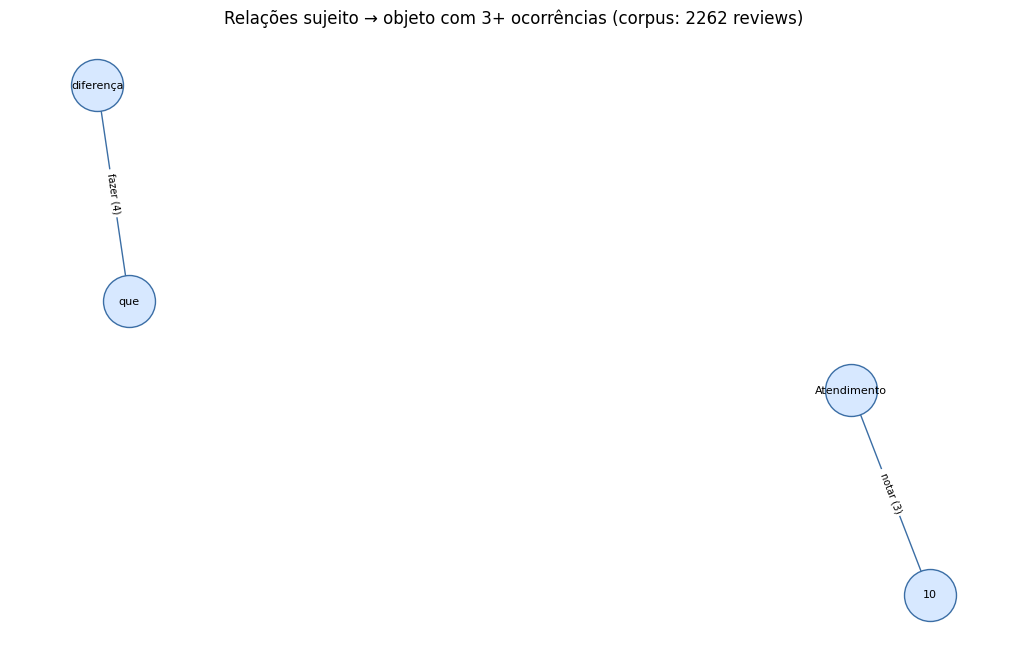

In [9]:
MIN_OCCURRENCES = 3

counts = (
    relations_df
    .groupby(["subject", "verb", "object"])
    .size()
    .reset_index(name="occurrences")
    .query("occurrences >= @MIN_OCCURRENCES")
)

print(
    f"Triplas repetidas ({MIN_OCCURRENCES}+ ocorrências) "
    f"no corpus de {RELATIONS_SAMPLE} reviews: {len(counts)}"
)

display(counts.sort_values("occurrences", ascending=False).reset_index(drop=True))

if counts.empty:
    print("Nenhuma relação se repete no corpus: o grafo fica vazio.")
else:
    # Constrói grafo com as relações
    # MultiDiGraph: dois verbos no mesmo par sujeito→objeto são arestas distintas
    graph = nx.MultiDiGraph()

    for _, row in counts.iterrows():
        graph.add_edge(
            row["subject"],
            row["object"],
            key=row["verb"],
            label=f"{row['verb']} ({row['occurrences']})"
        )

    plt.figure(figsize=(13, 8))
    layout = nx.spring_layout(graph, seed=42, k=0.9)

    nx.draw_networkx_nodes(
        graph,
        layout,
        node_size=1400,
        node_color="#d7e8ff",
        edgecolors="#3b6ea5"
    )
    nx.draw_networkx_labels(graph, layout, font_size=8)
    nx.draw_networkx_edges(
        graph,
        layout,
        arrows=True,
        arrowsize=12,
        edge_color="#3b6ea5"
    )
    nx.draw_networkx_edge_labels(
        graph,
        layout,
        edge_labels={
            (u, v, key): data["label"]
            for u, v, key, data in graph.edges(keys=True, data=True)
        },
        font_size=7
    )

    plt.title(
        "Relações sujeito → objeto com "
        f"{MIN_OCCURRENCES}+ ocorrências (corpus: {RELATIONS_SAMPLE} reviews)"
    )
    plt.axis("off")
    plt.show()


In [ ]:
def extract_aspect_opinions(doc):
    """Pares aspecto-opinião: "comida deliciosa" e "a comida estava deliciosa"."""
    records = []

    for token in doc:
        if token.pos_ not in {"NOUN", "PROPN"}:
            continue

        opinions = {
            child
            for child in token.children
            if child.pos_ == "ADJ" and child.dep_ in {"amod", "acomp", "oprd"}
        }

        # "a comida estava deliciosa": o adjetivo fica ligado ao verbo de ligação,
        # não ao substantivo, então sobe um nível pela cabeça do sujeito.
        if token.dep_ in {"nsubj", "nsubj:pass"}:
            head = token.head
            opinions.update(
                sibling
                for sibling in head.children
                if sibling.pos_ == "ADJ"
            )
            if head.pos_ == "ADJ":
                opinions.add(head)

        for opinion in opinions:
            records.append({
                "aspect": token.text,
                "opinion": opinion.text,
                "aspect_lemma": token.lemma_,
                "opinion_lemma": opinion.lemma_,
                "sentence": token.sent.text
            })

    return records


example_doc = nlp(texts[4])

aspect_records = extract_aspect_opinions(example_doc)

display(pd.DataFrame(aspect_records))

display(
    pd.DataFrame(
        extract_aspect_opinions(
            nlp("A comida estava deliciosa, mas o atendimento foi demorado.")
        )
    )
)


,aspect,opinion,aspect_lemma,opinion_lemma,sentence
0,Comida,maravilhosa,comida,maravilhoso,Comida maravilhosa.


,aspect,opinion,aspect_lemma,opinion_lemma,sentence
0,comida,deliciosa,comida,delicioso,"A comida estava deliciosa, mas o atendimento f..."


## Sentimento por aspectos

O corpus não tem anotação de sentimento, mas tem `rating`. A nota entra só como fonte de
polaridade para as opiniões já extraídas: opinião que aparece quase sempre em reviews de nota
4-5 é positiva, e em reviews de nota 1-2 é negativa.

Para o acerto não ser circular, metade das reviews monta o léxico e a outra metade serve de
teste. Não é léxico de domínio nem modelo de sentimento treinado: é polaridade derivada dos
rótulos, e deve ser lida assim.


In [ ]:
ASPECTS_SAMPLE = 300

aspects = []

for review_index, doc in enumerate(docs[:ASPECTS_SAMPLE]):
    for record in extract_aspect_opinions(doc):
        aspects.append({**record, "review_index": review_index})

aspects_df = pd.DataFrame(aspects)

ratings = preprocessed_reviews_df["rating"].astype(float)
aspects_df["rating"] = ratings.iloc[aspects_df["review_index"]].tolist()

print(f"Amostra: {ASPECTS_SAMPLE} reviews")
print(f"Pares aspecto-opinião: {len(aspects_df)}")
print(f"Reviews com pelo menos um par: {aspects_df['review_index'].nunique()}")

display(
    aspects_df["aspect_lemma"]
    .value_counts()
    .head(10)
    .rename("occurrences")
    .to_frame()
)

display(
    aspects_df
    .groupby(["aspect_lemma", "opinion_lemma"])
    .size()
    .reset_index(name="occurrences")
    .sort_values("occurrences", ascending=False)
    .head(15)
)

Amostra: 300 reviews
Pares aspecto-opinião: 274
Reviews com pelo menos um par: 153


,occurrences
aspect_lemma,
comida,51
atendimento,27
ambiente,22
lugar,18
restaurante,9
prato,8
experiência,5
almoço,5
risoto,4


,aspect_lemma,opinion_lemma,occurrences
65,comida,delicioso,9
35,atendimento,bom,9
66,comida,excelente,8
63,comida,bom,7
17,ambiente,agradável,6
74,comida,saboroso,6
60,comida,Boa,4
37,atendimento,excelente,4
13,almoço,excelente,3
40,atendimento,péssimo,3


In [ ]:
# Metade das reviews monta o léxico, metade fica de fora para o teste
rated = aspects_df[aspects_df["rating"].isin([1, 2, 4, 5])].copy()
rated["sentiment"] = rated["rating"].ge(4).map({True: "positive", False: "negative"})

polarity_lexicon = (
    rated[rated["review_index"] % 2 == 0]
    .pivot_table(
        index="opinion_lemma",
        columns="sentiment",
        values="review_index",
        aggfunc="count",
        fill_value=0
    )
    .reindex(columns=["positive", "negative"], fill_value=0)
)

polarity_lexicon["total"] = (
    polarity_lexicon["positive"] + polarity_lexicon["negative"]
)
polarity_lexicon["positive_rate"] = (
    polarity_lexicon["positive"] / polarity_lexicon["total"]
)

print(f"Opiniões distintas no léxico: {len(polarity_lexicon)}")

display(
    polarity_lexicon[polarity_lexicon["total"] >= 2]
    .sort_values("positive_rate")
)

Opiniões distintas no léxico: 57


sentiment,positive,negative,total,positive_rate
opinion_lemma,,,,
razoável,1,1,2,0.500000
agradável,6,1,7,0.857143
excelente,12,1,13,0.923077
bom,16,1,17,0.941176
Boa,4,0,4,1.000000
delicioso,5,0,5,1.000000
forte,2,0,2,1.000000
Bom,3,0,3,1.000000
grande,2,0,2,1.000000


In [ ]:
# Polaridade de cada aspecto: média da taxa positiva das suas opiniões
aspect_polarity = (
    aspects_df
    .merge(
        polarity_lexicon["positive_rate"],
        left_on="opinion_lemma",
        right_index=True,
        how="left"
    )
    .dropna(subset=["positive_rate"])
    .groupby("aspect_lemma")
    .agg(
        opinions=("positive_rate", "size"),
        polarity=("positive_rate", "mean")
    )
    .query("opinions >= 5")
    .sort_values("polarity")
)

print("Aspectos do mais negativo ao mais positivo (0 = negativo, 1 = positivo):")
display(aspect_polarity.round(3))

# Teste: opiniões conhecidas das reviews que não montaram o léxico, contra a nota
test_set = rated[rated["review_index"] % 2 == 1].copy()
test_set["polarity"] = test_set["opinion_lemma"].map(
    polarity_lexicon["positive_rate"]
)

review_polarity = (
    test_set
    .dropna(subset=["polarity"])
    .groupby("review_index")
    .agg(
        polarity=("polarity", "mean"),
        sentiment=("sentiment", "first")
    )
)

review_polarity["predicted"] = (
    review_polarity["polarity"].ge(0.5).map({True: "positive", False: "negative"})
)

print(f"Reviews de teste com opinião conhecida: {len(review_polarity)}")
print(
    "Acerto do sinal contra a nota: "
    f"{(review_polarity['predicted'] == review_polarity['sentiment']).mean():.1%}"
)

display(
    pd.crosstab(
        review_polarity["sentiment"],
        review_polarity["predicted"],
        rownames=["real"],
        colnames=["predicted"]
    )
)


Aspectos do mais negativo ao mais positivo (0 = negativo, 1 = positivo):


,opinions,polarity
aspect_lemma,,
atendimento,27,0.834
ambiente,17,0.935
almoço,5,0.954
lugar,15,0.967
restaurante,8,0.968
comida,43,0.976


Reviews de teste com opinião conhecida: 61
Acerto do sinal contra a nota: 95.1%


predicted,negative,positive
real,,
negative,1,2
positive,1,57


## Amostragem e limites

- **NER**: roda no corpus inteiro, sem amostragem.
- **Relações (SVO)**: corpus inteiro já parseado — a regra devolve poucas triplas por review,
  e o que interessa é a ordem de grandeza e a qualidade delas.
- **Aspectos e sentimento**: as mesmas 300 reviews, para manter uma amostra só.
- **Sentimento**: a polaridade vem do `rating` (1-2 negativa, 4-5 positiva) aplicado às
  opiniões, com metade das reviews montando o léxico e a outra metade testando.
- Reviews de nota 3 ficam fora: não são nem positivas nem negativas, então não servem de
  evidência de polaridade.
- O texto usado é o `review_text`, sem lematização nem remoção de stopwords: o parsing precisa
  da pontuação e da ordem originais.
